In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Зареждане
df = pd.read_csv(
    "data/traffic_combined.csv",
    parse_dates=["date"],
    low_memory=False
)

print(f"Редове  : {len(df):,}")
print(f"Колони  : {list(df.columns)}")
print(f"Период  : {df['date'].min()}  →  {df['date'].max()}")

Редове  : 12,239,528
Колони  : ['date', 'direction', 'plate', 'country', 'speed', 'vehicle_class', 'lane', 'length', 'weight']
Период  : 2022-01-01 00:00:18  →  2024-12-31 23:59:06


In [2]:
print("=" * 60)
print("СТЪПКА 1: ДУБЛИРАНИ ЗАПИСИ")
print("=" * 60)

# Пълни дубликати - всички колони съвпадат
full_duplicates = df.duplicated().sum()
print(f"Пълни дубликати (всички колони): {full_duplicates:,}")

# Дубликати по ключови колони - същото ПС в същия момент
key_duplicates = df.duplicated(subset=["date", "plate", "lane"]).sum()
print(f"Дубликати по date+plate+lane   : {key_duplicates:,}")

# Дубликати само по дата и лента (без plate)
date_lane_duplicates = df.duplicated(subset=["date", "lane"]).sum()
print(f"Дубликати по date+lane         : {date_lane_duplicates:,}")

# Примери на дубликати ако има такива
if full_duplicates > 0:
    print(f"\nПримери на пълни дубликати:")
    print(df[df.duplicated(keep=False)].head(10).to_string())
elif key_duplicates > 0:
    print(f"\nПримери на date+plate+lane дубликати:")
    print(df[df.duplicated(subset=["date","plate","lane"], keep=False)].head(10).to_string())

СТЪПКА 1: ДУБЛИРАНИ ЗАПИСИ
Пълни дубликати (всички колони): 742,026
Дубликати по date+plate+lane   : 746,280
Дубликати по date+lane         : 754,479

Примери на пълни дубликати:
                       date     direction     plate country  speed  vehicle_class lane  length  weight
410321  2022-01-26 05:04:23        Център       NaN     NaN     15              0   L1    3300       0
410322  2022-01-26 05:04:23        Център       NaN     NaN     15              0   L1    3300       0
790775  2022-02-25 17:07:43        Център       NaN     NaN     45              0   L1    5100       0
790776  2022-02-25 17:07:43        Център       NaN     NaN     45              0   L1    5100       0
951573  2022-04-16 13:19:08        Център  PB****AB     NaN     15              0   L1       0       0
951574  2022-04-16 13:19:08        Център  PB****AB     NaN     15              0   L1       0       0
974813  2022-04-21 00:44:15  Околовръстно       NaN     NaN     75              0   L4    4900      

In [3]:
print("=" * 60)
print("ПРЕМАХВАНЕ НА ДУБЛИКАТИ")
print("=" * 60)

df_clean = df.drop_duplicates().reset_index(drop=True)

print(f"Редове преди : {len(df):,}")
print(f"Редове след  : {len(df_clean):,}")
print(f"Премахнати   : {len(df) - len(df_clean):,} ({(len(df) - len(df_clean))/len(df)*100:.2f}%)")

# Проверка дали са останали дубликати
print(f"\nОстанали пълни дубликати: {df_clean.duplicated().sum():,}")
print(f"Останали date+plate+lane дубликати: {df_clean.duplicated(subset=['date','plate','lane']).sum():,}")

ПРЕМАХВАНЕ НА ДУБЛИКАТИ
Редове преди : 12,239,528
Редове след  : 11,497,502
Премахнати   : 742,026 (6.06%)

Останали пълни дубликати: 0
Останали date+plate+lane дубликати: 4,254


In [4]:
print("=" * 60)
print("АНАЛИЗ НА ОСТНАЛИТЕ ЧАСТИЧНИ ДУБЛИКАТИ")
print("=" * 60)

partial_dups = df_clean[df_clean.duplicated(subset=["date","plate","lane"], keep=False)]
print(f"Записи в частични дубликати: {len(partial_dups):,}")
print(f"\nПримери:")
print(partial_dups.sort_values(["date","plate","lane"]).head(20).to_string())

# Каква е разликата между тях?
print(f"\nРазлики в стойностите при частичните дубликати:")
for col in ["speed", "length", "weight", "direction", "country"]:
    nunique = (partial_dups.groupby(["date","plate","lane"])[col]
               .nunique()
               .gt(1)
               .sum())
    print(f"  {col}: {nunique} групи с различни стойности")

АНАЛИЗ НА ОСТНАЛИТЕ ЧАСТИЧНИ ДУБЛИКАТИ
Записи в частични дубликати: 8,474

Примери:
                     date direction plate country  speed  vehicle_class lane  length  weight
16731 2022-01-02 11:53:27       NaN   NaN     NaN     47              6  LN2    9800   19048
16733 2022-01-02 11:53:27       NaN   NaN     NaN     35              0  LN2    4900       0
49277 2022-01-03 18:55:37       NaN   NaN     NaN     44              0  LN2    3633    3036
49279 2022-01-03 18:55:37       NaN   NaN     NaN     57              1  LN2    4887    2806
60232 2022-01-04 11:00:16       NaN   NaN     NaN     44              1  LN5    3956     829
60233 2022-01-04 11:00:16       NaN   NaN     NaN     45              1  LN5    4777    1124
61356 2022-01-04 11:39:50    Център   NaN     NaN     49              0   L1    4900       0
61357 2022-01-04 11:39:50    Център   NaN     NaN     49              0   L1    3877       0
66446 2022-01-04 14:34:22       NaN   NaN     NaN     49              1  LN5   

In [5]:
print("=" * 60)
print("РЕШЕНИЕ ЗА ЧАСТИЧНИТЕ ДУБЛИКАТИ")
print("=" * 60)

# Проверка в кои ленти са концентрирани
print("Разпределение по лента:")
print(partial_dups["lane"].value_counts().to_string())

print(f"\nЧастичните дубликати са реални различни преминавания")
print(f"записани в същата секунда -> запазваме ги")
print(f"\nТекущ брой редове: {len(df_clean):,}")

РЕШЕНИЕ ЗА ЧАСТИЧНИТЕ ДУБЛИКАТИ
Разпределение по лента:
lane
L1     3809
L2     2519
L5     1004
L4      510
L6      418
L3      128
LN2      36
LN6      32
LN5      18

Частичните дубликати са реални различни преминавания
записани в същата секунда -> запазваме ги

Текущ брой редове: 11,497,502


In [6]:
print("=" * 60)
print("СТЪПКА 2: ФИЛТРИРАНЕ НА АНОМАЛИИ")
print("=" * 60)

# Преди филтриране
print(f"Редове преди филтриране: {len(df_clean):,}")

# --- SPEED ---
speed_zero    = (df_clean["speed"] == 0).sum()
speed_max     = (df_clean["speed"] == 255).sum()
print(f"\nSpeed = 0   : {speed_zero:,} ({speed_zero/len(df_clean)*100:.2f}%)")
print(f"Speed = 255 : {speed_max:,} ({speed_max/len(df_clean)*100:.2f}%)")

# --- LENGTH ---
length_invalid = (df_clean["length"] <= 0).sum()
length_max     = (df_clean["length"] >= 30000).sum()
print(f"\nLength <= 0      : {length_invalid:,} ({length_invalid/len(df_clean)*100:.2f}%)")
print(f"Length >= 30,000 : {length_max:,} ({length_max/len(df_clean)*100:.2f}%)")

# --- WEIGHT ---
weight_invalid = (df_clean["weight"] <= 0).sum()
weight_max     = (df_clean["weight"] >= 50000).sum()
print(f"\nWeight <= 0      : {weight_invalid:,} ({weight_invalid/len(df_clean)*100:.2f}%)")
print(f"Weight >= 50,000 : {weight_max:,} ({weight_max/len(df_clean)*100:.2f}%)")

# Общо засегнати записи (union)
anomaly_mask = (
    (df_clean["speed"] == 0) | (df_clean["speed"] == 255) |
    (df_clean["length"] <= 0) | (df_clean["length"] >= 30000) |
    (df_clean["weight"] <= 0) | (df_clean["weight"] >= 50000)
)
print(f"\nОбщо записи с поне 1 аномалия: {anomaly_mask.sum():,} ({anomaly_mask.sum()/len(df_clean)*100:.2f}%)")

СТЪПКА 2: ФИЛТРИРАНЕ НА АНОМАЛИИ
Редове преди филтриране: 11,497,502

Speed = 0   : 16,779 (0.15%)
Speed = 255 : 14,470 (0.13%)

Length <= 0      : 205,451 (1.79%)
Length >= 30,000 : 2,908 (0.03%)

Weight <= 0      : 1,381,259 (12.01%)
Weight >= 50,000 : 17,874 (0.16%)

Общо записи с поне 1 аномалия: 1,447,089 (12.59%)


In [7]:
print("=" * 60)
print("ИЗСЛЕДВАНЕ НА WEIGHT <= 0")
print("=" * 60)

w_zero = df_clean[df_clean["weight"] <= 0]

print(f"Записи с weight <= 0: {len(w_zero):,}")

print(f"\nРазпределение по vehicle_class:")
print(w_zero["vehicle_class"].value_counts().head(10).to_string())

print(f"\nРазпределение по lane:")
print(w_zero["lane"].value_counts().to_string())

print(f"\nСтатистика за speed при weight <= 0:")
print(w_zero["speed"].describe().round(1).to_string())

print(f"\nСтатистика за length при weight <= 0:")
print(w_zero["length"].describe().round(1).to_string())

# Дали weight=0 корелира с определени години?
print(f"\nРазпределение по година:")
print(w_zero["date"].dt.year.value_counts().sort_index().to_string())

# Процент weight=0 по година
for yr in [2022, 2023, 2024]:
    yr_mask = df_clean["date"].dt.year == yr
    pct = (df_clean[yr_mask]["weight"] <= 0).mean() * 100
    print(f"  {yr}: {pct:.1f}% от записите имат weight <= 0")

ИЗСЛЕДВАНЕ НА WEIGHT <= 0
Записи с weight <= 0: 1,381,259

Разпределение по vehicle_class:
vehicle_class
0    916574
1    356183
6     42030
2     30776
3     16314
5      9388
7      9109
4       885

Разпределение по lane:
lane
L4     522801
L5     442913
L1     371359
L2      31293
L6      11167
LN5       770
LN2       455
LN6       414
L3         83
LN3         4

Статистика за speed при weight <= 0:
count    1381259.0
mean          48.6
std           22.9
min            0.0
25%           41.0
50%           47.0
75%           53.0
max          255.0

Статистика за length при weight <= 0:
count    1381259.0
mean        3842.2
std         1888.8
min      -421800.0
25%         3100.0
50%         4300.0
75%         5200.0
max       111300.0

Разпределение по година:
date
2022     99198
2023    346589
2024    935472
  2022: 3.0% от записите имат weight <= 0
  2023: 5.7% от записите имат weight <= 0
  2024: 43.8% от записите имат weight <= 0


In [8]:
print("=" * 60)
print("WEIGHT=0 ПО ЛЕНТА И ГОДИНА")
print("=" * 60)

pivot = (df_clean.assign(year=df_clean["date"].dt.year,
                          weight_zero=(df_clean["weight"] <= 0).astype(int))
         .groupby(["year", "lane"])["weight_zero"]
         .mean()
         .mul(100)
         .round(1)
         .reset_index()
         .pivot(index="lane", columns="year", values="weight_zero"))

print("% записи с weight <= 0 по лента и година:")
print(pivot.to_string())

WEIGHT=0 ПО ЛЕНТА И ГОДИНА
% записи с weight <= 0 по лента и година:
year  2022  2023  2024
lane                  
L1     7.3  16.1  64.0
L2     0.4   0.7   1.9
L3     0.0   0.0   0.0
L4    16.2  53.8  90.5
L5     0.5   0.5  78.9
L6     1.3   1.3   1.4
LN2    0.2   NaN   NaN
LN3    0.0   NaN   NaN
LN5    0.5   NaN   NaN
LN6    1.2   NaN   NaN


In [9]:
print("=" * 60)
print("ФИЛТРИРАНЕ НА АНОМАЛИИ - SPEED И LENGTH")
print("=" * 60)

# Преди филтриране
print(f"Редове преди: {len(df_clean):,}")

# --- SPEED ---
# Премахваме speed=0 (спрели/грешка) и speed=255 (sensor overflow)
speed_mask = (df_clean["speed"] > 0) & (df_clean["speed"] < 255)

# --- LENGTH ---
# Премахваме отрицателни/нула и над 30,000мм (30м)
# Реалистичен диапазон: най-малкият мотоциклет ~1000мм, най-дългото МПС ~25,000мм
length_mask = (df_clean["length"] > 0) & (df_clean["length"] < 30000)

# Комбиниран филтър
combined_mask = speed_mask & length_mask
df_clean = df_clean[combined_mask].reset_index(drop=True)

print(f"Редове след : {len(df_clean):,}")
print(f"Премахнати  : {combined_mask.sum() - len(df_clean) + (~combined_mask).sum():,} "
      f"({(~combined_mask).sum()/combined_mask.size*100:.2f}%)")

# Верификация
print(f"\nВерификация след филтриране:")
print(f"Speed min/max   : {df_clean['speed'].min()} / {df_clean['speed'].max()}")
print(f"Length min/max  : {df_clean['length'].min()} / {df_clean['length'].max()}")
print(f"Speed = 0       : {(df_clean['speed'] == 0).sum():,}")
print(f"Speed = 255     : {(df_clean['speed'] == 255).sum():,}")
print(f"Length <= 0     : {(df_clean['length'] <= 0).sum():,}")
print(f"Length >= 30000 : {(df_clean['length'] >= 30000).sum():,}")

ФИЛТРИРАНЕ НА АНОМАЛИИ - SPEED И LENGTH
Редове преди: 11,497,502
Редове след : 11,271,815
Премахнати  : 225,687 (1.96%)

Верификация след филтриране:
Speed min/max   : 1 / 254
Length min/max  : 2 / 29999
Speed = 0       : 0
Speed = 255     : 0
Length <= 0     : 0
Length >= 30000 : 0


In [10]:
print("=" * 60)
print("СТЪПКА 3: НОРМАЛИЗИРАНЕ НА COUNTRY")
print("=" * 60)

print(f"Преди нормализиране:")
print(f"  BG  : {(df_clean['country'] == 'BG').sum():,}")
print(f"  BGR : {(df_clean['country'] == 'BGR').sum():,}")
print(f"  '-' : {(df_clean['country'] == '-').sum():,}")
print(f"  NaN : {df_clean['country'].isnull().sum():,}")

# BGR -> BG
df_clean['country'] = df_clean['country'].replace('BGR', 'BG')

# '-' -> NaN
df_clean['country'] = df_clean['country'].replace('-', np.nan)

print(f"\nСлед нормализиране:")
print(f"  BG  : {(df_clean['country'] == 'BG').sum():,}")
print(f"  BGR : {(df_clean['country'] == 'BGR').sum():,}")
print(f"  '-' : {(df_clean['country'] == '-').sum():,}")
print(f"  NaN : {df_clean['country'].isnull().sum():,}")

print(f"\nТоп 10 държави след нормализиране:")
print(df_clean['country'].value_counts().head(10).to_string())

СТЪПКА 3: НОРМАЛИЗИРАНЕ НА COUNTRY
Преди нормализиране:
  BG  : 5,480,931
  BGR : 1,013,363
  '-' : 172,955
  NaN : 4,320,311

След нормализиране:
  BG  : 6,494,294
  BGR : 0
  '-' : 0
  NaN : 4,493,266

Топ 10 държави след нормализиране:
country
BG    6494294
UA      63716
DE      28380
AT      25181
GB      19936
DK      19444
TR      15162
FR      13510
PL      10350
IT       9790


In [12]:
print("=" * 60)
print("СТЪПКА 4: ИЗСЛЕДВАНЕ НА МАРТ 2023")
print("=" * 60)

mar2023 = df_clean[
    (df_clean["date"].dt.year == 2023) & 
    (df_clean["date"].dt.month == 3)
]

print(f"Записи в Март 2023: {len(mar2023):,}")

# Сравнение с останалите месеци
monthly = (df_clean.groupby([df_clean["date"].dt.year.rename("year"), 
                              df_clean["date"].dt.month.rename("month")])
           .size()
           .reset_index(name="count"))

print(f"\nСредно записи/месец (без Март 2023): "
      f"{monthly[~((monthly['year']==2023) & (monthly['month']==3))]['count'].mean():,.0f}")
print(f"Записи Март 2023                    : {len(mar2023):,}")

# Дневна разбивка на Март 2023
print(f"\nДневни записи в Март 2023:")
daily_mar = mar2023.groupby(mar2023["date"].dt.day).size()
print(daily_mar.to_string())

СТЪПКА 4: ИЗСЛЕДВАНЕ НА МАРТ 2023
Записи в Март 2023: 753,498

Средно записи/месец (без Март 2023): 309,362
Записи Март 2023                    : 753,498

Дневни записи в Март 2023:
date
1     26335
2     26985
3     23144
4     21320
5     19874
6     26535
7     26739
8     28471
9     27060
10    28065
11    24599
12    22434
13    26280
14    26016
15    26337
16    26554
17    27506
18    24915
19    18671
20    22843
21    22967
22    23354
23    23599
24    24341
25    21573
26    18521
27    23065
28    23676
29    23860
30    23393
31    24466


In [13]:
print("=" * 60)
print("ОБОБЩЕНИЕ НА ПРЕДОБРАБОТКАТА")
print("=" * 60)

print(f"Оригинални записи        : 12,239,528")
print(f"След премахване дубликати: 11,497,502  (-742,026)")
print(f"След филтриране аномалии : 11,271,815  (-225,687)")
print(f"Текущи записи            : {len(df_clean):,}")
print(f"\nПремахнати общо          : {12239528 - len(df_clean):,} "
      f"({(12239528 - len(df_clean))/12239528*100:.1f}%)")

print(f"\nСтатус на колоните:")
print(f"  date          : чиста")
print(f"  direction     : 437,569 null (LN ленти)")
print(f"  plate         : null стойности (ще отпадне при агрегиране)")
print(f"  country       : null стойности (ще отпадне при агрегиране)")
print(f"  speed         : филтрирана (1-254 km/h)")
print(f"  vehicle_class : много рядко срещани класове")
print(f"  lane          : чиста")
print(f"  length        : филтрирана (1-29,999 мм)")
print(f"  weight        : системна повреда на сензора -> feature selection")

ОБОБЩЕНИЕ НА ПРЕДОБРАБОТКАТА
Оригинални записи        : 12,239,528
След премахване дубликати: 11,497,502  (-742,026)
След филтриране аномалии : 11,271,815  (-225,687)
Текущи записи            : 11,271,815

Премахнати общо          : 967,713 (7.9%)

Статус на колоните:
  date          : чиста
  direction     : 437,569 null (LN ленти)
  plate         : null стойности (ще отпадне при агрегиране)
  country       : null стойности (ще отпадне при агрегиране)
  speed         : филтрирана (1-254 km/h)
  vehicle_class : много рядко срещани класове
  lane          : чиста
  length        : филтрирана (1-29,999 мм)
  weight        : системна повреда на сензора -> feature selection


АНАЛИЗ НА OUTLIER-И


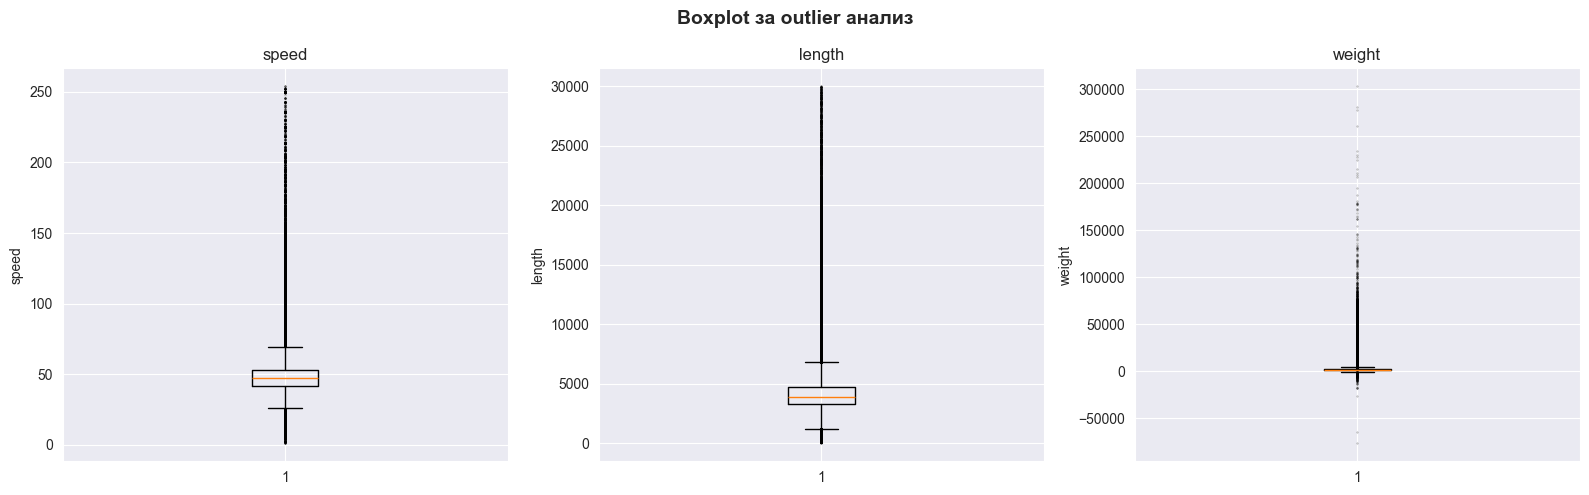


IQR анализ:

  speed:
    Q1=42.0, Q3=53.0, IQR=11.0
    Граници: [25.5, 69.5]
    Outlier-и: 546,875 (4.85%)

  length:
    Q1=3300.0, Q3=4700.0, IQR=1400.0
    Граници: [1200.0, 6800.0]
    Outlier-и: 614,928 (5.46%)

  weight:
    Q1=1022.0, Q3=2497.0, IQR=1475.0
    Граници: [-1190.5, 4709.5]
    Outlier-и: 727,047 (6.45%)


In [14]:
print("=" * 60)
print("АНАЛИЗ НА OUTLIER-И")
print("=" * 60)

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
fig.suptitle("Boxplot за outlier анализ", fontsize=14, fontweight="bold")

for ax, col in zip(axes, ["speed", "length", "weight"]):
    ax.boxplot(df_clean[col], showfliers=True, 
               flierprops=dict(marker=".", markersize=1, alpha=0.3))
    ax.set_title(col)
    ax.set_ylabel(col)

plt.tight_layout()
plt.savefig("outlier_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

# IQR метод
print("\nIQR анализ:")
for col in ["speed", "length", "weight"]:
    Q1  = df_clean[col].quantile(0.25)
    Q3  = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = ((df_clean[col] < lower) | (df_clean[col] > upper)).sum()
    print(f"\n  {col}:")
    print(f"    Q1={Q1:.1f}, Q3={Q3:.1f}, IQR={IQR:.1f}")
    print(f"    Граници: [{lower:.1f}, {upper:.1f}]")
    print(f"    Outlier-и: {outliers:,} ({outliers/len(df_clean)*100:.2f}%)")

In [15]:
print("=" * 60)
print("КАКВО СА OUTLIER-ИТЕ")
print("=" * 60)

# SPEED outliers
speed_low  = df_clean[df_clean["speed"] < 25.5]
speed_high = df_clean[df_clean["speed"] > 69.5]

print(f"SPEED < 25.5 km/h : {len(speed_low):,}")
print(f"SPEED > 69.5 km/h : {len(speed_high):,}")
print(f"\nРазпределение на speed > 69.5 по vehicle_class:")
print(speed_high["vehicle_class"].value_counts().head(8).to_string())
print(f"\nРазпределение на speed < 25.5 по vehicle_class:")
print(speed_low["vehicle_class"].value_counts().head(8).to_string())

# LENGTH outliers
length_low  = df_clean[df_clean["length"] < 1200]
length_high = df_clean[df_clean["length"] > 6800]

print(f"\nLENGTH < 1200 мм (< 1.2м) : {len(length_low):,}")
print(f"LENGTH > 6800 мм (> 6.8м)  : {len(length_high):,}")
print(f"\nРазпределение на length > 6800 по vehicle_class:")
print(length_high["vehicle_class"].value_counts().head(8).to_string())
print(f"\nРазпределение на length < 1200 по vehicle_class:")
print(length_low["vehicle_class"].value_counts().head(8).to_string())

# WEIGHT outliers (само горни - долните са отрицателни вече филтрирани)
weight_high = df_clean[df_clean["weight"] > 4709.5]
print(f"\nWEIGHT > 4709 кг : {len(weight_high):,}")
print(f"Разпределение по vehicle_class:")
print(weight_high["vehicle_class"].value_counts().head(8).to_string())

КАКВО СА OUTLIER-ИТЕ
SPEED < 25.5 km/h : 295,632
SPEED > 69.5 km/h : 251,243

Разпределение на speed > 69.5 по vehicle_class:
vehicle_class
1    170410
2     25992
0     24466
7     22491
3      2800
6      2789
5      2187
4        73

Разпределение на speed < 25.5 по vehicle_class:
vehicle_class
1    202305
0     32474
6     15293
5     14092
3     12152
2      8491
7      7801
4      2854

LENGTH < 1200 мм (< 1.2м) : 24,419
LENGTH > 6800 мм (> 6.8м)  : 590,509

Разпределение на length > 6800 по vehicle_class:
vehicle_class
5    158343
6    130822
3    118929
1     85861
2     48202
0     22787
4     12712
7      8481

Разпределение на length < 1200 по vehicle_class:
vehicle_class
7     12580
0      8661
5       984
3       958
6       604
1       552
30       62
4        15

WEIGHT > 4709 кг : 726,702
Разпределение по vehicle_class:
vehicle_class
1     216194
5     160854
6     129783
2     108664
3      85237
4      12332
7       7206
23      2617


In [16]:
print("=" * 60)
print("VEHICLE_CLASS — РЕДКИ КЛАСОВЕ")
print("=" * 60)

vc_counts = df_clean["vehicle_class"].value_counts().sort_values(ascending=False)
print("Всички класове:")
print(vc_counts.to_string())

print(f"\nКласове с под 1000 записа:")
rare = vc_counts[vc_counts < 1000]
print(rare.to_string())
print(f"\nОбщо редки класове : {len(rare)}")
print(f"Общо записи в тях  : {rare.sum():,} ({rare.sum()/len(df_clean)*100:.3f}%)")

VEHICLE_CLASS — РЕДКИ КЛАСОВЕ
Всички класове:
vehicle_class
1      9096322
0       855006
2       624146
5       191800
7       181831
3       157038
6       147171
4        13586
23        2618
30         491
35         466
22         317
40         220
9          197
21         180
19         108
18          58
10          43
34          29
28          29
11          24
41          22
403         22
13          19
24          15
55          13
31          12
43           7
26           7
32           5
60           4
42           3
66           3
20           1
53           1
29           1

Класове с под 1000 записа:
vehicle_class
30     491
35     466
22     317
40     220
9      197
21     180
19     108
18      58
10      43
34      29
28      29
11      24
41      22
403     22
13      19
24      15
55      13
31      12
43       7
26       7
32       5
60       4
42       3
66       3
20       1
53       1
29       1

Общо редки класове : 27
Общо записи в тях  : 2,297 (0.020%)


In [17]:
print("=" * 60)
print("ГРУПИРАНЕ НА РЕДКИ КЛАСОВЕ")
print("=" * 60)

# Класове с под 1000 записа -> 99
rare_classes = vc_counts[vc_counts < 1000].index.tolist()
df_clean["vehicle_class"] = df_clean["vehicle_class"].replace(
    {cls: 99 for cls in rare_classes}
)

print(f"Групирани класове: {rare_classes}")
print(f"\nРезултат след групиране:")
print(df_clean["vehicle_class"].value_counts().sort_values(ascending=False).to_string())

ГРУПИРАНЕ НА РЕДКИ КЛАСОВЕ
Групирани класове: [30, 35, 22, 40, 9, 21, 19, 18, 10, 34, 28, 11, 41, 403, 13, 24, 55, 31, 43, 26, 32, 60, 42, 66, 20, 53, 29]

Резултат след групиране:
vehicle_class
1     9096322
0      855006
2      624146
5      191800
7      181831
3      157038
6      147171
4       13586
23       2618
99       2297


In [18]:
print("=" * 60)
print("ПРОВЕРКА НА WEIGHT")
print("=" * 60)

print(f"Weight <= 0      : {(df_clean['weight'] <= 0).sum():,} ({(df_clean['weight'] <= 0).mean()*100:.2f}%)")
print(f"Weight < 0       : {(df_clean['weight'] < 0).sum():,}")
print(f"Weight = 0       : {(df_clean['weight'] == 0).sum():,}")
print(f"Weight >= 50,000 : {(df_clean['weight'] >= 50000).sum():,}")
print(f"\nMin weight: {df_clean['weight'].min():,}")
print(f"Max weight: {df_clean['weight'].max():,}")
print(f"\nОписателна статистика:")
print(df_clean["weight"].describe().round(1).to_string())

ПРОВЕРКА НА WEIGHT
Weight <= 0      : 1,204,523 (10.69%)
Weight < 0       : 9,892
Weight = 0       : 1,194,631
Weight >= 50,000 : 16,879

Min weight: -76,774
Max weight: 303,399

Описателна статистика:
count    11271815.0
mean         2368.3
std          4232.8
min        -76774.0
25%          1022.0
50%          1462.0
75%          2497.0
max        303399.0


In [19]:
print("=" * 60)
print("ФИЛТРИРАНЕ НА WEIGHT АНОМАЛИИ")
print("=" * 60)

print(f"Редове преди: {len(df_clean):,}")

# Филтрираме само явно невъзможните стойности
# weight=0 НЕ филтрираме — вече знаем че е системна повреда на сензора
# weight < 0 — физически невъзможно -> премахваме
# weight > 50,000 кг (50 тона) — над максималното допустимо за пътищата -> премахваме

weight_mask = (df_clean["weight"] >= 0) & (df_clean["weight"] < 50000)
df_clean = df_clean[weight_mask].reset_index(drop=True)

print(f"Редове след : {len(df_clean):,}")
print(f"Премахнати  : {weight_mask.size - weight_mask.sum():,} ({(~weight_mask).mean()*100:.2f}%)")

print(f"\nВерификация:")
print(f"Weight < 0       : {(df_clean['weight'] < 0).sum():,}")
print(f"Weight >= 50,000 : {(df_clean['weight'] >= 50000).sum():,}")
print(f"Min weight       : {df_clean['weight'].min():,}")
print(f"Max weight       : {df_clean['weight'].max():,}")

ФИЛТРИРАНЕ НА WEIGHT АНОМАЛИИ
Редове преди: 11,271,815
Редове след : 11,245,044
Премахнати  : 26,771 (0.24%)

Верификация:
Weight < 0       : 0
Weight >= 50,000 : 0
Min weight       : 0
Max weight       : 49,999


In [20]:
print("=" * 60)
print("LN ЛЕНТИ — ФИНАЛНО РЕШЕНИЕ")
print("=" * 60)

ln_mask = df_clean["lane"].str.startswith("LN")
print(f"LN записи общо: {ln_mask.sum():,} ({ln_mask.mean()*100:.2f}%)")
print(f"\nРазпределение по лента:")
print(df_clean[ln_mask]["lane"].value_counts().to_string())

print(f"\nСтатистика за LN записи:")
for col in ["speed", "length", "weight"]:
    print(f"  {col}: mean={df_clean[ln_mask][col].mean():.1f}, "
          f"std={df_clean[ln_mask][col].std():.1f}, "
          f"min={df_clean[ln_mask][col].min()}, "
          f"max={df_clean[ln_mask][col].max()}")

print(f"\nVehicle class при LN:")
print(df_clean[ln_mask]["vehicle_class"].value_counts().to_string())

print(f"\nDirection при LN:")
print(df_clean[ln_mask]["direction"].value_counts(dropna=False).to_string())

LN ЛЕНТИ — ФИНАЛНО РЕШЕНИЕ
LN записи общо: 435,928 (3.88%)

Разпределение по лента:
lane
LN2    195953
LN5    166348
LN3     38064
LN6     35563

Статистика за LN записи:
  speed: mean=46.9, std=9.1, min=5, max=236
  length: mean=4406.6, std=1762.8, min=200, max=29900
  weight: mean=2385.3, std=3663.1, min=0, max=49995

Vehicle class при LN:
vehicle_class
1     374799
0      28468
2      15644
5       7008
23      2448
99      2290
7       1951
6       1711
3       1486
4        123

Direction при LN:
direction
NaN    435928


In [21]:
print("=" * 60)
print("ДЕТАЙЛЕН АНАЛИЗ НА LN ЛЕНТИ")
print("=" * 60)

# Кога са се появили LN записите - по година и месец
print("LN записи по година:")
print(df_clean[ln_mask]["date"].dt.year.value_counts().sort_index().to_string())

print("\nLN записи по месец (всички години):")
print(df_clean[ln_mask]["date"].dt.month.value_counts().sort_index().to_string())

# Дали LN и L записите се появяват едновременно?
print("\nПример - LN2 и L2 в един и същи час:")
df_clean["hour_ts"] = df_clean["date"].dt.floor("h")
ln2_hours = set(df_clean[df_clean["lane"] == "LN2"]["hour_ts"])
l2_hours  = set(df_clean[df_clean["lane"] == "L2"]["hour_ts"])
overlap   = ln2_hours & l2_hours
print(f"  Часове с LN2 записи : {len(ln2_hours):,}")
print(f"  Часове с L2 записи  : {len(l2_hours):,}")
print(f"  Часове с И ДВЕТЕ    : {len(overlap):,}")
print(f"  Overlap %           : {len(overlap)/len(ln2_hours)*100:.1f}%")

# Дали LN се появява само в определени периоди?
print("\nПърви и последен LN запис:")
print(f"  Първи : {df_clean[ln_mask]['date'].min()}")
print(f"  Последен: {df_clean[ln_mask]['date'].max()}")

# Дали има периоди само с LN без L?
print("\nЧасове САМО с LN (без нито един L запис):")
l_hours  = set(df_clean[~ln_mask]["hour_ts"])
only_ln  = ln2_hours - l_hours
print(f"  {len(only_ln):,} часа само с LN2 записи")

ДЕТАЙЛЕН АНАЛИЗ НА LN ЛЕНТИ
LN записи по година:
date
2022    435928

LN записи по месец (всички години):
date
1    432848
2      3080

Пример - LN2 и L2 в един и същи час:
  Часове с LN2 записи : 543
  Часове с L2 записи  : 9,727
  Часове с И ДВЕТЕ    : 1
  Overlap %           : 0.2%

Първи и последен LN запис:
  Първи : 2022-01-01 00:00:18
  Последен: 2022-02-01 14:39:44

Часове САМО с LN (без нито един L запис):
  264 часа само с LN2 записи


In [22]:
print("=" * 60)
print("ПРЕИМЕНУВАНЕ НА LN ЛЕНТИ")
print("=" * 60)

lane_mapping = {
    "LN2": "L2",
    "LN5": "L5",
    "LN3": "L3",
    "LN6": "L6"
}

df_clean["lane"] = df_clean["lane"].replace(lane_mapping)

print("След преименуване:")
print(df_clean["lane"].value_counts().sort_index().to_string())

# Премахване на временната колона
df_clean = df_clean.drop(columns=["hour_ts"])

print(f"\nNull в direction след преименуване: {df_clean['direction'].isnull().sum():,}")

ПРЕИМЕНУВАНЕ НА LN ЛЕНТИ
След преименуване:
lane
L1    1326428
L2    3936849
L3     750384
L4     949089
L5    3412035
L6     870259

Null в direction след преименуване: 435,928


In [23]:
print("=" * 60)
print("ПОПЪЛВАНЕ НА DIRECTION ПО LANE")
print("=" * 60)

lane_to_direction = {
    "L1": "Център",      "L2": "Център",      "L3": "Център",
    "L4": "Околовръстно", "L5": "Околовръстно", "L6": "Околовръстно"
}

# Попълване само на null стойностите
null_dir_before = df_clean["direction"].isnull().sum()

df_clean["direction"] = df_clean.apply(
    lambda row: lane_to_direction.get(row["lane"], row["direction"]) 
    if pd.isnull(row["direction"]) else row["direction"],
    axis=1
)

null_dir_after = df_clean["direction"].isnull().sum()

print(f"Null преди : {null_dir_before:,}")
print(f"Null след  : {null_dir_after:,}")
print(f"Попълнени  : {null_dir_before - null_dir_after:,}")

print(f"\nРазпределение на direction след попълване:")
print(df_clean["direction"].value_counts(dropna=False).to_string())

ПОПЪЛВАНЕ НА DIRECTION ПО LANE
Null преди : 435,928
Null след  : 0
Попълнени  : 435,928

Разпределение на direction след попълване:
direction
Център          6013661
Околовръстно    5231383


In [24]:
print("=" * 60)
print("ПРОВЕРКА НА DATE")
print("=" * 60)

print(f"Период      : {df_clean['date'].min()}  →  {df_clean['date'].max()}")
print(f"Null в date : {df_clean['date'].isnull().sum():,}")

# Записи извън очаквания период 2022-2024
outside = df_clean[
    (df_clean["date"].dt.year < 2022) | 
    (df_clean["date"].dt.year > 2024)
]
print(f"\nЗаписи извън 2022-2024: {len(outside):,}")
if len(outside) > 0:
    print(outside["date"].dt.year.value_counts().sort_index().to_string())

# Дублирани timestamps (различни записи в абсолютно същия момент и лента)
print(f"\nЗаписи по година след предобработката:")
print(df_clean["date"].dt.year.value_counts().sort_index().to_string())

# Проверка за нереалистични timestamps - напр. далеч в бъдещето или миналото
print(f"\nРазпределение по месец и година:")
monthly = (df_clean.groupby([df_clean["date"].dt.year.rename("year"),
                              df_clean["date"].dt.month.rename("month")])
           .size()
           .reset_index(name="count"))
print(monthly.to_string(index=False))

ПРОВЕРКА НА DATE
Период      : 2022-01-01 00:00:18  →  2024-12-31 23:59:06
Null в date : 0

Записи извън 2022-2024: 0

Записи по година след предобработката:
date
2022    3230373
2023    5993283
2024    2021388

Разпределение по месец и година:
 year  month  count
 2022      1 499930
 2022      2 298764
 2022      3  73262
 2022      4 182742
 2022      5 294651
 2022      6 573354
 2022      7  96123
 2022      8 299316
 2022      9 559133
 2022     10     39
 2022     11 126449
 2022     12 226610
 2023      1 289707
 2023      2 549340
 2023      3 752320
 2023      4 605730
 2023      5 315831
 2023      6 755365
 2023      7 264654
 2023      8 328907
 2023      9  62085
 2023     10 682095
 2023     11 742770
 2023     12 644479
 2024      1 230521
 2024      2     21
 2024      3 218311
 2024      4 228144
 2024      5  57792
 2024      6  55404
 2024      7  52697
 2024      8   3194
 2024     10 341534
 2024     11  63697
 2024     12 770073


In [25]:
print("=" * 60)
print("1. КОНСИСТЕНТНОСТ LANE ↔ DIRECTION")
print("=" * 60)

lane_dir = (df_clean.groupby(["lane", "direction"])
            .size()
            .reset_index(name="count"))

lane_dir_pivot = lane_dir.pivot(index="lane", columns="direction", values="count").fillna(0)
lane_dir_pivot["total"] = lane_dir_pivot.sum(axis=1)

for col in ["Център", "Околовръстно"]:
    lane_dir_pivot[f"{col}_%"] = (lane_dir_pivot[col] / lane_dir_pivot["total"] * 100).round(2)

print(lane_dir_pivot.to_string())

1. КОНСИСТЕНТНОСТ LANE ↔ DIRECTION
direction  Околовръстно     Център      total  Център_%  Околовръстно_%
lane                                                                   
L1                  0.0  1326428.0  1326428.0     100.0             0.0
L2                  0.0  3936849.0  3936849.0     100.0             0.0
L3                  0.0   750384.0   750384.0     100.0             0.0
L4             949089.0        0.0   949089.0       0.0           100.0
L5            3412035.0        0.0  3412035.0       0.0           100.0
L6             870259.0        0.0   870259.0       0.0           100.0


In [26]:
print("=" * 60)
print("2. АНАЛИЗ НА VEHICLE_CLASS = 0")
print("=" * 60)

vc0 = df_clean[df_clean["vehicle_class"] == 0]
vc1 = df_clean[df_clean["vehicle_class"] == 1]

print(f"Клас 0 записи: {len(vc0):,} ({len(vc0)/len(df_clean)*100:.2f}%)")

print(f"\nСравнение клас 0 vs клас 1:")
for col in ["speed", "length", "weight"]:
    print(f"\n  {col}:")
    print(f"    Клас 0: mean={vc0[col].mean():.1f}, median={vc0[col].median():.1f}, std={vc0[col].std():.1f}")
    print(f"    Клас 1: mean={vc1[col].mean():.1f}, median={vc1[col].median():.1f}, std={vc1[col].std():.1f}")

print(f"\nРазпределение по lane:")
print(vc0["lane"].value_counts().to_string())

print(f"\nРазпределение по година:")
print(vc0["date"].dt.year.value_counts().sort_index().to_string())

print(f"\nWeight = 0 при клас 0:")
print(f"  {(vc0['weight'] == 0).sum():,} ({(vc0['weight'] == 0).mean()*100:.1f}%)")
print(f"Weight = 0 при клас 1:")
print(f"  {(vc1['weight'] == 0).sum():,} ({(vc1['weight'] == 0).mean()*100:.1f}%)")

2. АНАЛИЗ НА VEHICLE_CLASS = 0
Клас 0 записи: 854,588 (7.60%)

Сравнение клас 0 vs клас 1:

  speed:
    Клас 0: mean=46.0, median=44.0, std=16.6
    Клас 1: mean=47.7, median=47.0, std=9.5

  length:
    Клас 0: mean=4060.8, median=3700.0, std=1345.3
    Клас 1: mean=3797.8, median=3800.0, std=1120.6

  weight:
    Клас 0: mean=113.0, median=0.0, std=966.3
    Клас 1: mean=1827.4, median=1455.0, std=1462.7

Разпределение по lane:
lane
L5    426677
L1    308395
L4     71698
L2     38492
L6      9147
L3       179

Разпределение по година:
date
2022     66350
2023    100358
2024    687880

Weight = 0 при клас 0:
  815,870 (95.5%)
Weight = 0 при клас 1:
  339,847 (3.7%)


In [27]:
print("=" * 60)
print("3. ПРОВЕРКА НА PLATE")
print("=" * 60)

print(f"Общо записи       : {len(df_clean):,}")
print(f"Null в plate      : {df_clean['plate'].isnull().sum():,} ({df_clean['plate'].isnull().mean()*100:.2f}%)")
print(f"Уникални номера   : {df_clean['plate'].nunique():,}")

# Дължина на номерата
plate_lengths = df_clean["plate"].dropna().str.len()
print(f"\nДължина на регистрационните номера:")
print(plate_lengths.value_counts().sort_index().to_string())

# Нереалистично къси или дълги
print(f"\nНомера с дължина < 3 символа:")
short = df_clean[df_clean["plate"].str.len() < 3].dropna(subset=["plate"])
print(f"  {len(short):,} записа")
if len(short) > 0:
    print(short["plate"].value_counts().head(10).to_string())

print(f"\nНомера с дължина > 12 символа:")
long_plates = df_clean[df_clean["plate"].str.len() > 12].dropna(subset=["plate"])
print(f"  {len(long_plates):,} записа")
if len(long_plates) > 0:
    print(long_plates["plate"].value_counts().head(10).to_string())

# Специални символи
print(f"\nНомера съдържащи само цифри (подозрително):")
only_digits = df_clean["plate"].dropna().str.match(r"^\d+$").sum()
print(f"  {only_digits:,} записа")

3. ПРОВЕРКА НА PLATE
Общо записи       : 11,245,044
Null в plate      : 2,686,921 (23.89%)
Уникални номера   : 1,117,974

Дължина на регистрационните номера:
plate
1      172906
2        2097
3        6916
4       48389
5       69037
6      124435
7      777280
8     7277903
9       77924
10        267
11         62
12         79
13         45
14         47
15         55
16         42
17         80
18        109
19        121
20         81
21         66
22         62
23         48
24         28
25         44

Номера с дължина < 3 символа:
  175,003 записа
plate
-     172664
PB       199
11       123
اا        51
77        51
4         41
1         40
ا         33
7         30
1ا        28

Номера с дължина > 12 символа:
  828 записа
plate
06YMMПPEB031ПA0BM            2
ABT06YCH1ПPEB03MПA0          2
MAPUJPYTHAПMHMA              2
ABT06YCHMПPEB031IA0BMB       2
MAPUPYTHAПMHMA               2
111111ا1II11ا                1
A806YCHP1ПPEB031ПA0B         1
1I1I1I1II1I1I1I111I1111I1    1
ABT

In [28]:
print("=" * 60)
print("ПОЧИСТВАНЕ НА PLATE")
print("=" * 60)

# Преди
print(f"Null преди: {df_clean['plate'].isnull().sum():,}")

# '-' -> NaN
df_clean["plate"] = df_clean["plate"].replace("-", np.nan)

# Дължина < 3 или > 12 -> NaN (нереалистични)
plate_len = df_clean["plate"].str.len()
df_clean.loc[plate_len < 3, "plate"] = np.nan
df_clean.loc[plate_len > 12, "plate"] = np.nan

# След
print(f"Null след : {df_clean['plate'].isnull().sum():,} ({df_clean['plate'].isnull().mean()*100:.2f}%)")
print(f"Уникални номера след: {df_clean['plate'].nunique():,}")

print(f"\nДължина на номерата след почистване:")
print(df_clean["plate"].dropna().str.len().value_counts().sort_index().to_string())

ПОЧИСТВАНЕ НА PLATE
Null преди: 2,686,921
Null след : 2,862,752 (25.46%)
Уникални номера след: 1,116,567

Дължина на номерата след почистване:
plate
3        6916
4       48389
5       69037
6      124435
7      777280
8     7277903
9       77924
10        267
11         62
12         79


In [29]:
print("=" * 60)
print("4. ВРЕМЕВА КОНСИСТЕНТНОСТ")
print("=" * 60)

# Дали записите са наредени хронологично
is_sorted = df_clean["date"].is_monotonic_increasing
print(f"Хронологично наредени: {is_sorted}")

if not is_sorted:
    df_clean = df_clean.sort_values("date").reset_index(drop=True)
    print("Сортирани по дата")

# Дали има дублирани timestamps изобщо
dup_timestamps = df_clean.duplicated(subset=["date", "lane"]).sum()
print(f"Дублирани date+lane  : {dup_timestamps:,}")

# Минимален интервал между записи в една лента
print(f"\nМинимален интервал между записи по лента (секунди):")
for lane in ["L1", "L2", "L3", "L4", "L5", "L6"]:
    lane_dates = df_clean[df_clean["lane"] == lane]["date"].sort_values()
    min_diff = lane_dates.diff().dt.total_seconds().dropna()
    print(f"  {lane}: min={min_diff.min():.0f}s, "
          f"median={min_diff.median():.0f}s, "
          f"mean={min_diff.mean():.1f}s")

4. ВРЕМЕВА КОНСИСТЕНТНОСТ
Хронологично наредени: True
Дублирани date+lane  : 9,585

Минимален интервал между записи по лента (секунди):
  L1: min=0s, median=18s, mean=71.4s
  L2: min=0s, median=5s, mean=24.1s
  L3: min=0s, median=22s, mean=126.2s
  L4: min=0s, median=15s, mean=99.8s
  L5: min=0s, median=3s, mean=27.8s
  L6: min=0s, median=10s, mean=108.8s


In [30]:
print("=" * 60)
print("5. ФИНАЛНА СТАТИСТИКА ПРЕДИ/СЛЕД")
print("=" * 60)

print(f"{'Метрика':<35} {'Преди':>15} {'След':>15}")
print("-" * 65)
print(f"{'Общо записи':<35} {'12,239,528':>15} {len(df_clean):>15,}")
print(f"{'Уникални ленти':<35} {'10 (L+LN)':>15} {df_clean['lane'].nunique():>15}")
print(f"{'Уникални vehicle_class':<35} {'38':>15} {df_clean['vehicle_class'].nunique():>15}")
print(f"{'Null в direction':<35} {'437,569':>15} {df_clean['direction'].isnull().sum():>15,}")
print(f"{'Null в country':<35} {'4,891,734':>15} {df_clean['country'].isnull().sum():>15,}")
print(f"{'Null в plate':<35} {'3,144,809':>15} {df_clean['plate'].isnull().sum():>15,}")
print(f"{'BGR записи':<35} {'1,139,232':>15} {(df_clean['country'] == 'BGR').sum():>15,}")
print(f"{'Записи със speed=0 или 255':<35} {'31,249':>15} {((df_clean['speed']==0)|(df_clean['speed']==255)).sum():>15,}")
print(f"{'Записи с length<=0':<35} {'213,801':>15} {(df_clean['length']<=0).sum():>15,}")
print(f"{'Записи с weight<0':<35} {'?':>15} {(df_clean['weight']<0).sum():>15,}")

print(f"\nОписателна статистика след предобработката:")
print(df_clean[["speed", "length", "weight"]].describe().round(2).to_string())

5. ФИНАЛНА СТАТИСТИКА ПРЕДИ/СЛЕД
Метрика                                       Преди            След
-----------------------------------------------------------------
Общо записи                              12,239,528      11,245,044
Уникални ленти                            10 (L+LN)               6
Уникални vehicle_class                           38              10
Null в direction                            437,569               0
Null в country                            4,891,734       4,477,783
Null в plate                              3,144,809       2,862,752
BGR записи                                1,139,232               0
Записи със speed=0 или 255                   31,249               0
Записи с length<=0                          213,801               0
Записи с weight<0                                 ?               0

Описателна статистика след предобработката:
             speed       length       weight
count  11245044.00  11245044.00  11245044.00
mean         47.65

In [31]:
print("=" * 60)
print("6. ТЕМПОРАЛНА КОНСИСТЕНТНОСТ")
print("=" * 60)

# Средна скорост по час и ден - търсим аномални стойности
df_clean["hour"] = df_clean["date"].dt.hour
df_clean["dow"]  = df_clean["date"].dt.dayofweek
df_clean["date_only"] = df_clean["date"].dt.date

# Дневен брой записи - търсим аномални дни
daily = df_clean.groupby("date_only").agg(
    count        = ("speed", "size"),
    avg_speed    = ("speed", "mean"),
    avg_length   = ("length", "mean")
).reset_index()

print(f"Дневна статистика:")
print(f"  Средно записи/ден  : {daily['count'].mean():,.0f}")
print(f"  Std записи/ден     : {daily['count'].std():,.0f}")
print(f"  Min записи/ден     : {daily['count'].min():,}")
print(f"  Max записи/ден     : {daily['count'].max():,}")

# Дни с необичайно малко записи (под 10% от средното)
threshold_low  = daily["count"].mean() * 0.10
threshold_high = daily["count"].mean() * 3.0

anomaly_days_low  = daily[daily["count"] < threshold_low]
anomaly_days_high = daily[daily["count"] > threshold_high]

print(f"\nДни с под 10% от средния брой записи ({threshold_low:,.0f}):")
print(f"  {len(anomaly_days_low):,} дни")
print(anomaly_days_low.sort_values("count").head(20).to_string(index=False))

print(f"\nДни с над 300% от средния брой записи ({threshold_high:,.0f}):")
print(f"  {len(anomaly_days_high):,} дни")
print(anomaly_days_high.sort_values("count", ascending=False).head(10).to_string(index=False))

6. ТЕМПОРАЛНА КОНСИСТЕНТНОСТ
Дневна статистика:
  Средно записи/ден  : 13,798
  Std записи/ден     : 10,821
  Min записи/ден     : 1
  Max записи/ден     : 32,467

Дни с под 10% от средния брой записи (1,380):
  74 дни
 date_only  count  avg_speed  avg_length
2024-02-01      1       19.0      5100.0
2024-01-27      1       41.0      5000.0
2024-01-17      1       63.0      5800.0
2024-01-14      1       44.0      5500.0
2024-08-15      1       56.0      5700.0
2024-08-07      1       48.0      4700.0
2024-08-03      1       56.0      5500.0
2024-08-06      1       44.0      4900.0
2024-08-17      1       51.0      5900.0
2024-02-08      2       43.0      5100.0
2024-02-04      2       32.5      6850.0
2024-02-03      2       54.5      5550.0
2024-01-21      2       67.5      3950.0
2024-01-25      2       40.0      5300.0
2024-01-26      2       53.0      4850.0
2024-01-29      2       54.5      5550.0
2024-08-08      2       52.0      5050.0
2024-08-12      2       45.5      5100.0
20

In [32]:
print("=" * 60)
print("АНАЛИЗ НА ДНИТЕ С МАЛКО ЗАПИСИ")
print("=" * 60)

# Дали тези дни са в началото/края на известни gap-ове?
anomaly_days_low["date_only"] = pd.to_datetime(anomaly_days_low["date_only"])

print("Разпределение по година:")
print(anomaly_days_low["date_only"].dt.year.value_counts().sort_index().to_string())

print("\nРазпределение по месец:")
print(anomaly_days_low["date_only"].dt.month.value_counts().sort_index().to_string())

# Средна скорост по час - търсим аномални часове
hourly_speed = (df_clean.groupby("hour")["speed"]
                .agg(["mean", "std", "count"])
                .round(2))

print(f"\nСредна скорост по час:")
print(hourly_speed.to_string())

# Има ли часове с необичайно висока/ниска средна скорост?
speed_mean = hourly_speed["mean"].mean()
speed_std  = hourly_speed["mean"].std()
anomaly_hours = hourly_speed[
    (hourly_speed["mean"] > speed_mean + 2*speed_std) |
    (hourly_speed["mean"] < speed_mean - 2*speed_std)
]
print(f"\nАномални часове (извън 2σ): {len(anomaly_hours)}")
if len(anomaly_hours) > 0:
    print(anomaly_hours.to_string())

АНАЛИЗ НА ДНИТЕ С МАЛКО ЗАПИСИ
Разпределение по година:
date_only
2022    23
2023    10
2024    41

Разпределение по месец:
date_only
1     15
2     10
3      1
5      6
6      2
7     20
8     15
9      4
10     1

Средна скорост по час:
       mean    std   count
hour                      
0     48.50  13.27  138056
1     48.16  14.41   80486
2     48.62  15.38   63266
3     49.52  16.29   65999
4     49.65  15.71   81419
5     47.87  14.15  121525
6     47.66  12.36  228950
7     48.11  11.25  561543
8     47.78  11.01  593196
9     47.38  10.46  581278
10    47.28  10.25  638744
11    47.42  10.41  715503
12    47.67  10.38  751497
13    47.53  10.33  763700
14    47.61  10.33  764407
15    47.63  10.37  772999
16    47.51  10.21  822663
17    47.15  10.16  874961
18    47.40  10.32  797747
19    47.74  10.73  651495
20    47.99  11.17  464621
21    47.90  11.86  311294
22    48.08  12.39  215250
23    48.39  12.97  184445

Аномални часове (извън 2σ): 2
       mean    std  count
ho

In [33]:
# Премахване на помощните колони
df_clean = df_clean.drop(columns=["hour", "dow", "date_only"])

df_clean.to_csv("data/traffic_preprocessed.csv", index=False)
print(f"Запазено в data/traffic_preprocessed.csv")
print(f"Редове : {len(df_clean):,}")
print(f"Колони : {list(df_clean.columns)}")

Запазено в data/traffic_preprocessed.csv
Редове : 11,245,044
Колони : ['date', 'direction', 'plate', 'country', 'speed', 'vehicle_class', 'lane', 'length', 'weight']
